# Inactive Users Analysis
Analysis of accounts in Moodle that have not been active in 2024, 2025 and 2026

In [46]:
# dependencies
import pandas as pd
import numpy as np
from datetime import datetime
from datetime import timedelta
import re
import matplotlib.pyplot as plt
import seaborn as sns

## Moodle

In [ ]:
# import data
user_path = 'C:/Users/ywa/OneDrive - Stifterverband/Dokumente/Data/MoodleUser/Jul2026/Users.xlsx'

users_pd = pd.read_excel(user_path)

users_pd.head()

In [91]:
# number of users who never logged in 
inactive = len(users_pd.loc[users_pd['Last access'] == 'Never'])

print(f"There {inactive} inactive users on Moodle")


There 29 inactive users on Moodle


In [92]:
# list of active learners
active_df = users_pd.loc[~(users_pd['Last access'] == 'Never')]

print(users_pd.shape)
print(active.shape)

(121963, 3)
(121934, 3)


In [106]:
# number of active users of the year
active = active_df.loc[~(active_df['Last access'].str.contains('year'))]

active_users = len(active)


In [ ]:
# list of active learners with the last access more than one year
year_user = active_df.loc[(active_df['Last access'].str.contains('year'))]
year_user

In [108]:
# preprocessing Last access column
year_split = year_user['Last access'].str.split('year')

year_user['year'] = [x[0] for x in year_split]


C:\Users\ywa\AppData\Local\Temp\ipykernel_28972\3765517605.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  year_user['year'] = [x[0] for x in year_split]


In [ ]:
year_user['year'] = year_user['year'].str.strip().astype('int')

year_user.head()

In [ ]:
# regular expression
day_reg = r'(\d+)\s+day[s]?'

day_split = year_user['Last access'].str.extract(day_reg)[0].fillna(0).astype(int)

year_user['day'] = day_split

year_user.head()

In [ ]:
# using timedelta to get year
year_user['year_day'] = pd.Timestamp.now() - pd.to_timedelta((year_user['year'] * 365.25 + year_user['day']), unit = 'D') 

year_user.head()

In [ ]:
year_user['date'] = year_user['year_day'].dt.year
year_user.head()

In [116]:
# last access
user_2024 = len(year_user.loc[year_user['date'] < 2024])

# last access 2025
user_2025 = len(year_user.loc[year_user['date'] < 2025])

# last access 2026
user_2026 = len(year_user.loc[year_user['date'] < 2026])

print(f"{user_2024} users haven't been active since 2024, {user_2025} users haven't been active in 2025, {user_2026} users haven't been active in 2026")


1968 users haven't been active since 2024, 13313 users haven't been active in 2025, 36660 users haven't been active in 2026


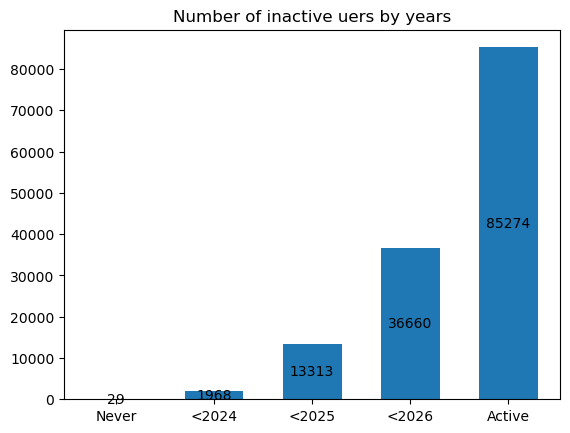

In [117]:
# plot the numbers of not active users
x = ['Never', '<2024', '<2025', '<2026', 'Active']
y = [inactive, user_2024, user_2025, user_2026, active_users]

width = 0.6

fig, ax = plt.subplots()
plot = ax.bar(x, y, width)
ax.bar_label(plot, label_type = 'center')

ax.set_title('Number of inactive uers by years')
plt.show()



## Drupal

In [ ]:
# import data
drupal_path = 'C:/Users/ywa/OneDrive - Stifterverband/Dokumente/Data/MoodleUser/Jul2026/drupal_users.csv'

drupal_pd = pd.read_csv(drupal_path)

drupal_pd.head()

In [34]:
#  check user status
print(drupal_pd["Benutzerstatus"].unique())

['On']


In [31]:
# clean last login column
# strip the weekday
drupal_pd["year_day"] = drupal_pd["Letzte Anmeldung"].str.split(",").str[1]

drupal_pd["year_day"] = drupal_pd["year_day"].str.replace(".", "/")


In [33]:
# formatting the datatime
drupal_pd["year_day"] = pd.to_datetime(drupal_pd["year_day"].str.strip(), format='mixed')

drupal_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190609 entries, 0 to 190608
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   name                190607 non-null  object        
 1   field_firstname     190556 non-null  object        
 2   field_lastname      190554 non-null  object        
 3   field_organisation  40214 non-null   object        
 4   mail                190609 non-null  object        
 5   Benutzerstatus      190609 non-null  object        
 6   Letzte Anmeldung    190609 non-null  object        
 7   year_day            190609 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(7)
memory usage: 11.6+ MB


In [37]:
# extract year
drupal_pd["year"] = drupal_pd["year_day"].dt.year
drupal_pd["year"]

0         2026
1         2020
2         2023
3         2023
4         2024
          ... 
190604    2026
190605    2026
190606    2026
190607    2026
190608    2026
Name: year, Length: 190609, dtype: int32

In [38]:
# last access 2021
drupal_2021 = len(drupal_pd.loc[drupal_pd["year"] < 2021])

# last access 2022
drupal_2022 = len(drupal_pd.loc[drupal_pd["year"] < 2022])

# last access 2023
drupal_2023 = len(drupal_pd.loc[drupal_pd["year"] < 2023])

# last access 2024
drupal_2024 = len(drupal_pd.loc[drupal_pd["year"] < 2024])

# last access 2025
drupal_2025 = len(drupal_pd.loc[drupal_pd["year"] < 2025])

# last access 2026
drupal_2026 = len(drupal_pd.loc[drupal_pd["year"] < 2026])

print(f"{drupal_2021} users haven't been active since 2021, {drupal_2022} users haven't been active since 2022, {drupal_2023} users haven't been active since 2023, {drupal_2024} users haven't been active since 2024, {drupal_2025} users haven't been active in 2025, {drupal_2026} users haven't been active in 2026")


2726 users haven't been active since 2021, 9324 users haven't been active since 2022, 15972 users haven't been active since 2023, 33049 users haven't been active since 2024, 61100 users haven't been active in 2025, 114862 users haven't been active in 2026


In [43]:
# Active learners 2026
drupal_active = len(drupal_pd.loc[drupal_pd["year"] == 2026])

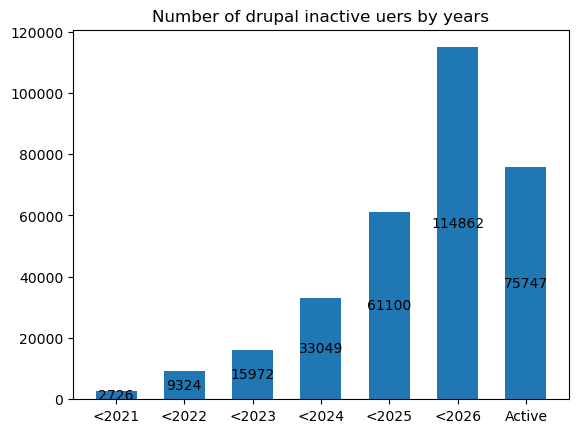

In [67]:
# plot the numbers of not active users
x_drupal = ['<2021', '<2022', '<2023', '<2024', '<2025', '<2026', 'Active']
y_drupal = [drupal_2021, drupal_2022, drupal_2023, drupal_2024, drupal_2025, drupal_2026, drupal_active]

width = 0.6

fig, ax = plt.subplots()
plot_drupal = ax.bar(x_drupal, y_drupal, width)
ax.bar_label(plot_drupal, label_type = 'center')

ax.set_title('Number of drupal inactive uers by years')
plt.show()